In [48]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

In [49]:
x_data = np.array([ [73., 80., 75.],
                    [93., 88., 93.], 
                    [89., 91., 90.], 
                    [96., 98., 100.], 
                    [73., 66., 70.]
                ])

y_data = np.array([ [152.],
                    [185.],
                    [180.],
                    [196.],
                    [142.]
                ])


# 기존 데이터의 평균
x_mean = np.mean(x_data, axis=0)

# 표준편차를 구한다
x_std = np.std(x_data, axis=0)

# 표준화 시킨 데이터 
x_scaled = (x_data - x_mean) / x_std

In [50]:
model = tf.keras.Sequential()

# 입력 레이어 추가 
model.add(tf.keras.Input(shape=(3,)))

# 출력 레이어 추가 -> activation 는 linear(선형 회기)
model.add(tf.keras.layers.Dense(units=1, activation='linear'))


# 데이터를 표준화 시켜서 0.1 사용가능 
# 표준화 시키지 않았다면 1e-5 정도 사용하면 된다
model.compile(
  optimizer = tf.keras.optimizers.SGD(learning_rate=0.1), # 사용할 최적화 알고리즘 sgd:확률적 경사하강법
  loss = 'mse'  # 손실함수 
)

model.summary()

Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_5 (Dense)                 │ (None, 1)              │             4 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4 (16.00 B)

 Trainable params: 4 (16.00 B)

 Non-trainable params: 0 (0.00 B)

In [51]:
start_weights = model.layers[0].get_weights()
print(f"학습전 : w {start_weights[0]}, b {start_weights[1]}")




학습전 : w [[-0.7131233 ]
 [ 0.6774291 ]
 [-0.54845643]], b [0.]


In [52]:
# 4. fit 메소드로 트레이닝
# 학습 
loss =  model.fit(x_scaled, y_data, epochs=100)

Epoch 1/100


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 99ms/step - loss: 29687.1758
Epoch 2/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - loss: 18795.9277
Epoch 3/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - loss: 11993.0977
Epoch 4/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - loss: 7669.4482
Epoch 5/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step - loss: 4907.7271
Epoch 6/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - loss: 3141.1831
Epoch 7/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - loss: 2010.7520
Epoch 8/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step - loss: 1287.2888
Epoch 9/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - loss: 824.2612
Epoch 10/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - loss: 527.9072
Epoch 11/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - loss: 338.2250
Epoch 12/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - loss: 216.8129
Epoch 13/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - loss: 139.0944
Epoch 14/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - loss: 89.3407
Epoch 15/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - loss: 

In [53]:
# 학습을 통해 구한 w와 b의 값
end_weights = model.layers[0].get_weights()
end_weights

print(f"학습후 : w {end_weights[0]}, b {end_weights[1]}")

학습후 : w [[8.454783 ]
 [5.125368 ]
 [7.3093357]], b [170.99997]


Text(0, 0.5, 'Loss')

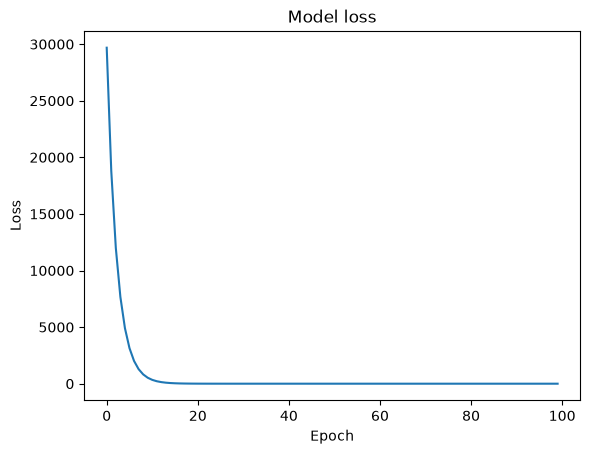

In [54]:
plt.plot(loss.history['loss'])
plt.title('Model loss')

# 반복 횟수 
plt.xlabel('Epoch')

# 손실값 
plt.ylabel('Loss')

In [59]:

# 예측 테스트도 표준화 한 데이터로 만들어서 테스트 
x_test = np.array([[80., 85., 90.], [81., 50., 40.] ])
# x_test = np.array([[80., 85., 90.]])
x_test_scaled = (x_test - x_mean) / x_std
print(model.predict(x_test_scaled))

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step
[[169.93163]
 [122.02611]]
